# Social Sciences & Communications Audit

## Load the records used in the salary visualizations

`csu_salary_schedule_joined.parquet` contains the 2024 payroll records already matched to salary schedule rows by `csu_data_prep.ipynb`, including its title/rank rules and unmatched records. Load that saved join directly to preserve the assigned ranges. The schedule CSV is loaded separately for inspection and restricted to effective dates through December 31, 2024, as in the preparation notebook.

`csu_salary_joined_df` retains all saved records. `plot_df` reproduces the preparation notebook's visualization filters and annualized bounds. `ss_comms_df` contains only academic-year full professors (matched Range Title = PROFESSOR and an academic-year instructional faculty classification) in Social Sciences & Communication; assistant and associate professors are excluded. Bounds use monthly rates times Annual Factor; they are not FTE-adjusted or prorated.


In [2]:
from pathlib import Path
import pandas as pd

# Resolve paths when running from the audit folder or the repository root.
repo_root = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "Models" / "Data" / "csu_salary_schedule_joined.parquet").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Run this notebook from within the CSC4693 repository.")
data_dir = repo_root / "Models" / "Data"

csu_salary_joined_df = pd.read_parquet(data_dir / "csu_salary_schedule_joined.parquet")
salary_schedule_df = pd.read_csv(data_dir / "csu-salary-schedule.csv")
salary_schedule_df["Effective Date"] = pd.to_datetime(
    salary_schedule_df["Effective Date"], format="%m/%d/%Y", errors="coerce"
)
salary_schedule_df = salary_schedule_df.loc[
    salary_schedule_df["Effective Date"].le(pd.Timestamp("2024-12-31"))
].copy().reset_index(drop=True)

assert pd.to_numeric(csu_salary_joined_df["year_transparentCA"], errors="coerce").eq(2024).all()
print(f"Loaded {len(csu_salary_joined_df):,} joined 2024 records and {len(salary_schedule_df):,} eligible schedule rows.")


Loaded 11,060 joined 2024 records and 568 eligible schedule rows.


In [3]:
# Same transformations and eligibility rules as csu_data_prep.ipynb.
plot_df = csu_salary_joined_df.copy()
for column in ["base_pay", "Min Salary", "Max Salary", "Annual Factor"]:
    plot_df[column] = pd.to_numeric(
        plot_df[column].astype("string").str.replace(r"[$,]", "", regex=True),
        errors="coerce",
    )

# Annualize monthly schedules using the factor supplied in the CSV.
monthly = plot_df["Salary Per"].astype("string").str.strip().eq("M")
plot_df["salary_low"] = (plot_df["Min Salary"] * plot_df["Annual Factor"]).where(monthly)
plot_df["salary_high"] = (plot_df["Max Salary"] * plot_df["Annual Factor"]).where(monthly)
plot_df["Range Title"] = plot_df["Range Title"].astype("string").str.strip().replace("", pd.NA)

eligible = (
    plot_df["year_transparentCA"].eq(2024)
    & plot_df["salary_match"].eq("both")
    & plot_df["base_pay"].notna()
    & plot_df["department"].notna()
    & plot_df["Range Title"].notna()
    & plot_df["Annual Factor"].gt(0)
    & plot_df["salary_low"].gt(0)
    & plot_df["salary_high"].ge(plot_df["salary_low"])
)
plot_coverage = pd.DataFrame({
    "records": [len(plot_df), int(eligible.sum()), int((~eligible).sum())]
}, index=["Joined records", "Plotted records", "Missing range, pay, department, or usable monthly bounds"])
plot_df = plot_df.loc[eligible].copy()
plot_df["below_range"] = plot_df["base_pay"].lt(plot_df["salary_low"])
plot_df["above_range"] = plot_df["base_pay"].gt(plot_df["salary_high"])
plot_coverage


,records
Joined records,11060
Plotted records,10601
"Missing range, pay, department, or usable monthly bounds",459


In [4]:
# Compare academic-year full professors under the same salary schedule.
ss_comms_df = plot_df.loc[
    plot_df["department"].eq("Social Sciences & Communication")
    & plot_df["Range Title"].str.casefold().eq("professor")
    & plot_df["Class Title"].astype("string").str.fullmatch(
        r"\s*INSTRUCTIONAL FACULTY\s*-\s*ACADEMIC YEAR\s*\*?\s*",
        case=False, na=False,
    )
].copy()

# Use these same bounds for both charts and the below-minimum DataFrame.
bounds = ss_comms_df[["salary_low", "salary_high"]].drop_duplicates()
assert len(bounds) == 1, "Expected one matched academic-year professor salary band."
minimum, maximum = bounds.iloc[0]
assert ss_comms_df["Range Title"].str.casefold().eq("professor").all()

print(f"Social Sciences & Communication academic-year full-professor records: {len(ss_comms_df):,}")
display(ss_comms_df[[
    "name", "school", "year_transparentCA", "title", "job", "department",
    "Class Title", "Range Title", "Effective Date", "match_method",
    "base_pay", "salary_low", "salary_high", "below_range", "above_range",
]].head(10))


Social Sciences & Communication academic-year full-professor records: 667


,name,school,year_transparentCA,title,job,department,Class Title,Range Title,Effective Date,match_method,base_pay,salary_low,salary_high,below_range,above_range
7,Alemseghed Kebede,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,131010,103116.0,182532.0,False,False
9,Alexander Reid,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,90586,103116.0,182532.0,True,False
21,Andy Alali,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,58570,103116.0,182532.0,True,False
22,Andy Alali,CSU Bakersfield,2024,Professor Emeritus,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,58570,103116.0,182532.0,True,False
27,Anne Duran,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,132985,103116.0,182532.0,False,False
30,Anthony Flores,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,104883,103116.0,182532.0,False,False
34,Ashleigh Herrera,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,76022,103116.0,182532.0,True,False
45,Carol Raupp,CSU Bakersfield,2024,Professor Emeritus,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,248,103116.0,182532.0,True,False
55,Dana Stewart,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,85981,103116.0,182532.0,True,False
70,Doreen Anderson-Facile,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Social Sciences & Communication,INSTRUCTIONAL FACULTY - ACADEMIC YEAR,PROFESSOR,2024-07-01,job plus compatible title rank,49470,103116.0,182532.0,True,False


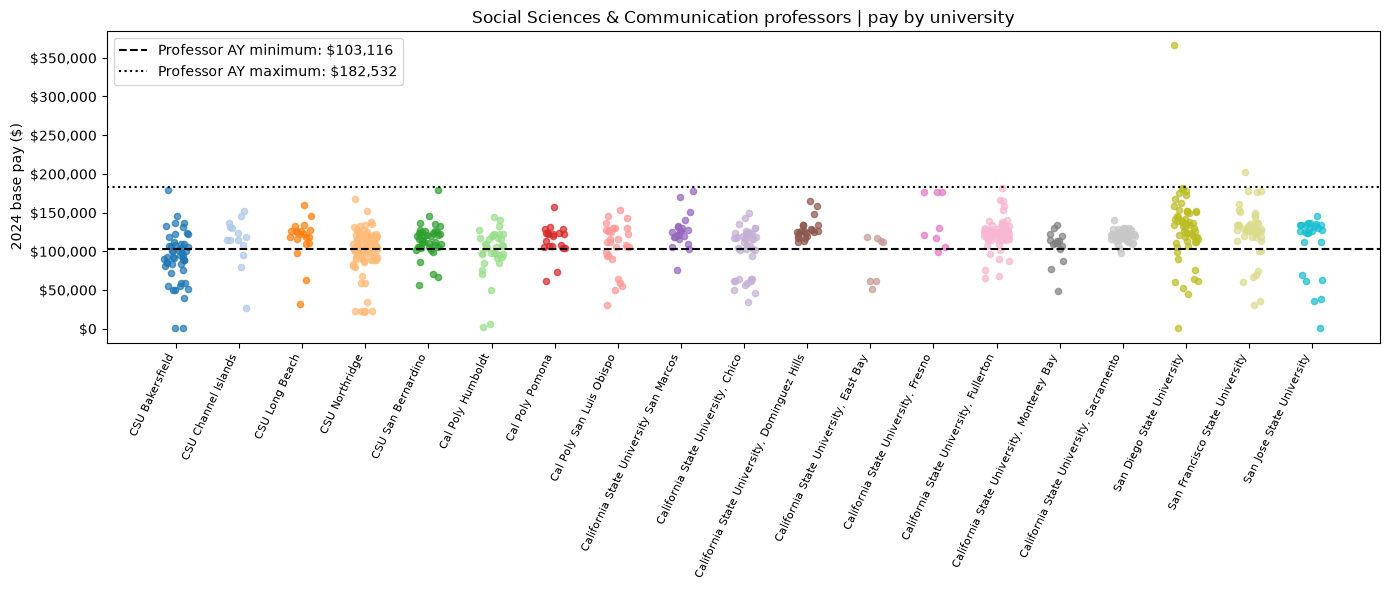

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, ax = plt.subplots(figsize=(14, 6))
rng = np.random.default_rng(42)
universities = sorted(ss_comms_df["school"].dropna().unique())
for i, university in enumerate(universities):
    pay = ss_comms_df.loc[ss_comms_df["school"].eq(university), "base_pay"]
    ax.scatter(i + rng.uniform(-0.2, 0.2, len(pay)), pay,
               color=plt.get_cmap("tab20")(i % 20), s=20, alpha=0.7, label=university)

ax.axhline(minimum, color="black", linestyle="--",
           label=f"Professor AY minimum: ${minimum:,.0f}")
ax.axhline(maximum, color="black", linestyle=":",
           label=f"Professor AY maximum: ${maximum:,.0f}")
ax.set_xticks(range(len(universities)), universities, rotation=65, ha="right", fontsize=8)
ax.set_ylabel("2024 base pay ($)")
ax.set_title("Social Sciences & Communication professors | pay by university")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[-2:], labels[-2:])
fig.tight_layout()
plt.show()


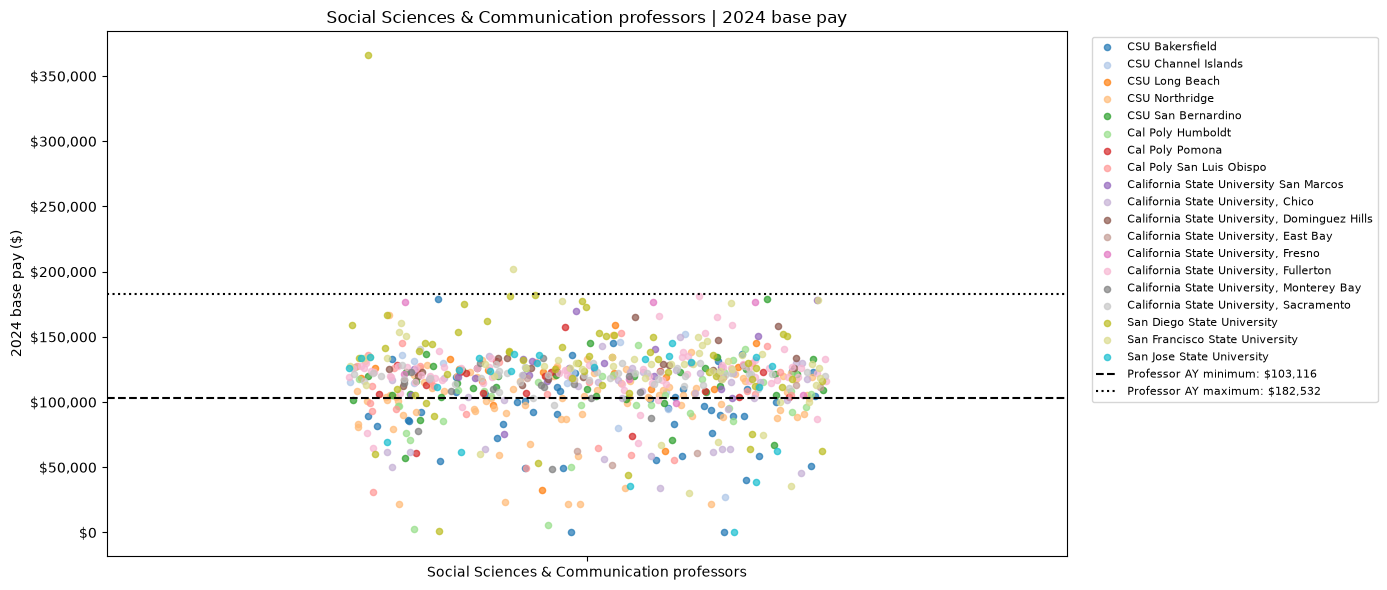

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, ax = plt.subplots(figsize=(14, 6))
rng = np.random.default_rng(42)
universities = sorted(ss_comms_df["school"].dropna().unique())
for i, university in enumerate(universities):
    pay = ss_comms_df.loc[ss_comms_df["school"].eq(university), "base_pay"]
    ax.scatter(rng.uniform(-0.25, 0.25, len(pay)), pay,
               color=plt.get_cmap("tab20")(i % 20), s=20, alpha=0.7, label=university)

ax.axhline(minimum, color="black", linestyle="--",
           label=f"Professor AY minimum: ${minimum:,.0f}")
ax.axhline(maximum, color="black", linestyle=":",
           label=f"Professor AY maximum: ${maximum:,.0f}")
ax.set_xticks([0], ["Social Sciences & Communication professors"])
ax.set_xlim(-0.5, 0.5)
ax.set_ylabel("2024 base pay ($)")
ax.set_title("Social Sciences & Communication professors | 2024 base pay")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
fig.tight_layout()
plt.show()


In [7]:
ss_comms_df

,year_transparentCA,school,name,title,job,original_department,department,total_pay,base_pay,overtime_pay,...,Step 28,Step 29,Step 30,Step 31,Step 32,salary_match,salary_low,salary_high,below_range,above_range
7,2024,CSU Bakersfield,Alemseghed Kebede,Professor,instructional faculty - academic year,Sociology,Social Sciences & Communication,161606,131010,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,False,False
9,2024,CSU Bakersfield,Alexander Reid,Professor,instructional faculty - academic year,"Human Development, and Child, Adolescent, and ...",Social Sciences & Communication,97586,90586,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
21,2024,CSU Bakersfield,Andy Alali,Professor,instructional faculty - academic year,Communications,Social Sciences & Communication,69109,58570,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
22,2024,CSU Bakersfield,Andy Alali,Professor Emeritus,instructional faculty - academic year,Communications,Social Sciences & Communication,69109,58570,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
27,2024,CSU Bakersfield,Anne Duran,Professor,instructional faculty - academic year,Psychology,Social Sciences & Communication,144346,132985,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10659,2024,San Jose State University,Shinchieh Duh,Professor,instructional faculty - academic year,Psychology,Social Sciences & Communication,117013,111426,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,False,False
10670,2024,San Jose State University,Stephanie Coopman,Professor,instructional faculty - academic year,Communication Studies,Social Sciences & Communication,69359,69359,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
10689,2024,San Jose State University,Tabitha Hart,Professor,instructional faculty - academic year,Communication Studies,Social Sciences & Communication,150757,123955,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,False,False
10694,2024,San Jose State University,Tanya Saroj Bakhru,Professor,instructional faculty - academic year,"Gender, and Sexuality Studies Program",Social Sciences & Communication,143175,130465,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,False,False


In [8]:
# Full professors in Social Sciences & Communication below the chart's minimum.
ss_comms_below_min_df = ss_comms_df.loc[
    ss_comms_df["base_pay"].lt(minimum)
].copy().sort_values("base_pay").reset_index(drop=True)

print(f"{len(ss_comms_below_min_df):,} professors below ${minimum:,.0f}")
ss_comms_below_min_df


166 professors below $103,116


,year_transparentCA,school,name,title,job,original_department,department,total_pay,base_pay,overtime_pay,...,Step 28,Step 29,Step 30,Step 31,Step 32,salary_match,salary_low,salary_high,below_range,above_range
0,2024,CSU Bakersfield,Judith Pratt,Professor Emeritus,instructional faculty - academic year,Communications,Social Sciences & Communication,171,171,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
1,2024,CSU Bakersfield,Carol Raupp,Professor Emeritus,instructional faculty - academic year,Psychology,Social Sciences & Communication,248,248,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
2,2024,San Jose State University,Toni Campbell,Chair,instructional faculty - academic year,Child & Adolescent Development,Social Sciences & Communication,267,267,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
3,2024,San Diego State University,Todd Braje,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,939,939,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
4,2024,Cal Poly Humboldt,Laura Hahn,Professor,instructional faculty - academic year,Communication,Social Sciences & Communication,2410,2410,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161,2024,California State University San Marcos,Andrew Spieldenner,Professor,instructional faculty - academic year,Communication,Social Sciences & Communication,113438,102879,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
162,2024,CSU Northridge,Gary Katz,Professor,instructional faculty - academic year,Psychology,Social Sciences & Communication,116397,102903,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
163,2024,CSU Northridge,Chin-Hsin Liu,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,102970,102970,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
164,2024,"California State University, Monterey Bay",Christine Valdez,Professor,instructional faculty - academic year,Psychology,Social Sciences & Communication,126045,103062,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False


In [9]:
# Preserve the five professors from the displayed random sample.
sampled_professors = pd.DataFrame([
    ("Gisela Lanzas", "CSU Northridge"),
    ("Marisa Sanchez", "CSU Bakersfield"),
    ("Christine Valdez", "California State University, Monterey Bay"),
    ("Breny Mendoza", "CSU Northridge"),
    ("Edna Molina", "CSU Bakersfield"),
], columns=["name", "school"])
sampled_professors_df = sampled_professors.merge(
    ss_comms_below_min_df, on=["name", "school"], how="left", validate="one_to_many"
)
sampled_professors_df


,name,school,year_transparentCA,title,job,original_department,department,total_pay,base_pay,overtime_pay,...,Step 28,Step 29,Step 30,Step 31,Step 32,salary_match,salary_low,salary_high,below_range,above_range
0,Gisela Lanzas,CSU Northridge,2024,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,89894,79297,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
1,Marisa Sanchez,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Sociology,Social Sciences & Communication,120435,100629,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
2,Christine Valdez,"California State University, Monterey Bay",2024,Professor,instructional faculty - academic year,Psychology,Social Sciences & Communication,126045,103062,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
3,Breny Mendoza,CSU Northridge,2024,Professor,instructional faculty - academic year,Gender and Women’s Studies,Social Sciences & Communication,124181,97815,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False
4,Edna Molina,CSU Bakersfield,2024,Professor,instructional faculty - academic year,Sociology,Social Sciences & Communication,55567,55157,0,...,NaN,NaN,NaN,NaN,NaN,both,103116.0,182532.0,True,False


In [10]:
# Enter the name and school exactly as shown in the audit (case does not matter).
lookup_name = "Gisela Lanzas"
lookup_school = "CSU Northridge"

model_history_df = pd.read_parquet(
    data_dir / "model_csu_depbucket_cleaned_joined_pay_2013-2024.parquet"
)
name_match = model_history_df["name"].astype("string").str.strip().str.casefold().eq(
    lookup_name.strip().casefold()
)
school_match = model_history_df["school"].astype("string").str.strip().str.casefold().eq(
    lookup_school.strip().casefold()
)
years = pd.to_numeric(model_history_df["year_transparentCA"], errors="coerce")
faculty_history_df = (
    model_history_df.loc[name_match & school_match & years.between(2013, 2024)]
    .sort_values("year_transparentCA")
    .reset_index(drop=True)
)

if not lookup_name.strip() or not lookup_school.strip():
    print("Enter lookup_name and lookup_school above, then rerun this cell.")
elif faculty_history_df.empty:
    print("No records found for that name and school.")
    print("Schools found for this name:", model_history_df.loc[name_match, "school"].dropna().unique().tolist())
else:
    display(faculty_history_df)


,year_transparentCA,school,name,title,job,original_department,department,total_pay,base_pay,overtime_pay,other_pay
0,2014,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,16157,15415,0,741
1,2015,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,71908,65858,0,6050
2,2016,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,72359,66859,0,5500
3,2017,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,82135,77910,0,4225
4,2018,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,74124,72124,0,2000
5,2019,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,86184,74243,0,11941
6,2020,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,77746,76581,0,1165
7,2021,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,63616,62616,0,1000
8,2022,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,564,564,0,0
9,2023,CSU Northridge,Gisela Lanzas,Professor,instructional faculty - academic year,Anthropology,Social Sciences & Communication,22596,22596,0,0


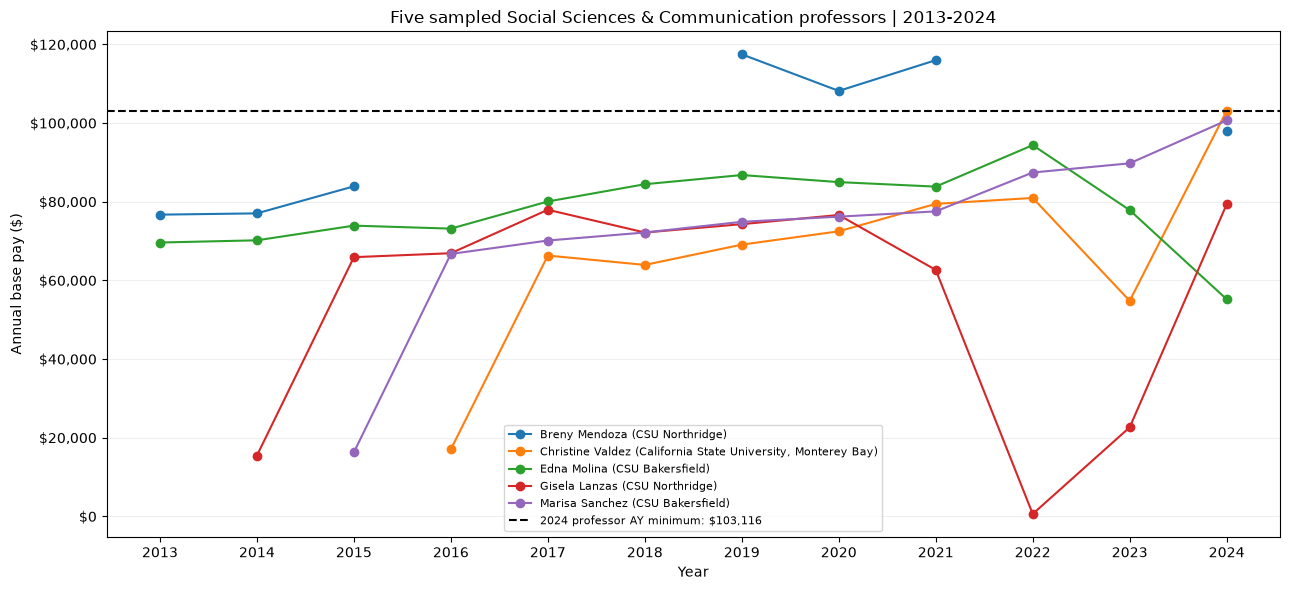

In [11]:
# Pay history for the same five professors, matched by both name and school.
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

sampled_history_df = model_history_df.merge(
    sampled_professors, on=["name", "school"], how="inner", validate="many_to_one"
).copy()
sampled_history_df["year_transparentCA"] = pd.to_numeric(
    sampled_history_df["year_transparentCA"], errors="coerce"
)
sampled_history_df["base_pay"] = pd.to_numeric(sampled_history_df["base_pay"], errors="coerce")
sampled_history_df = sampled_history_df.loc[
    sampled_history_df["year_transparentCA"].between(2013, 2024)
].sort_values(["name", "school", "year_transparentCA"])

fig, ax = plt.subplots(figsize=(13, 6))
for (name, school), group in sampled_history_df.groupby(["name", "school"]):
    # Leave missing years as gaps rather than treating them as zero pay.
    pay_by_year = group.set_index("year_transparentCA")["base_pay"].reindex(range(2013, 2025))
    ax.plot(pay_by_year.index, pay_by_year, marker="o", label=f"{name} ({school})")

ax.axhline(minimum, color="black", linestyle="--",
           label=f"2024 professor AY minimum: ${minimum:,.0f}")
ax.set_xticks(range(2013, 2025))
ax.set_xlabel("Year")
ax.set_ylabel("Annual base pay ($)")
ax.set_title("Five sampled Social Sciences & Communication professors | 2013-2024")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="y", alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


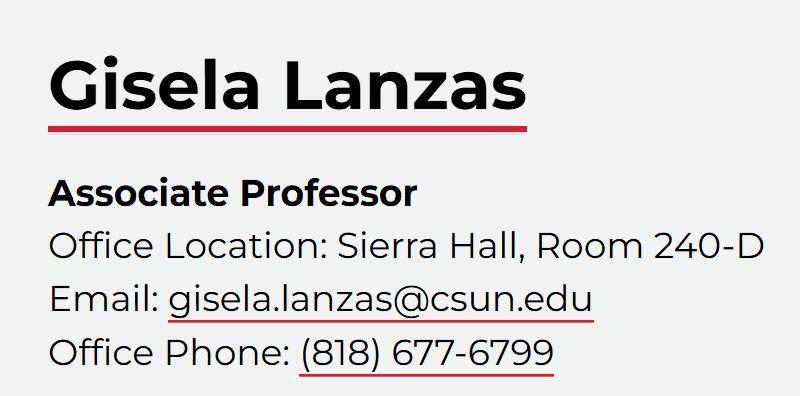
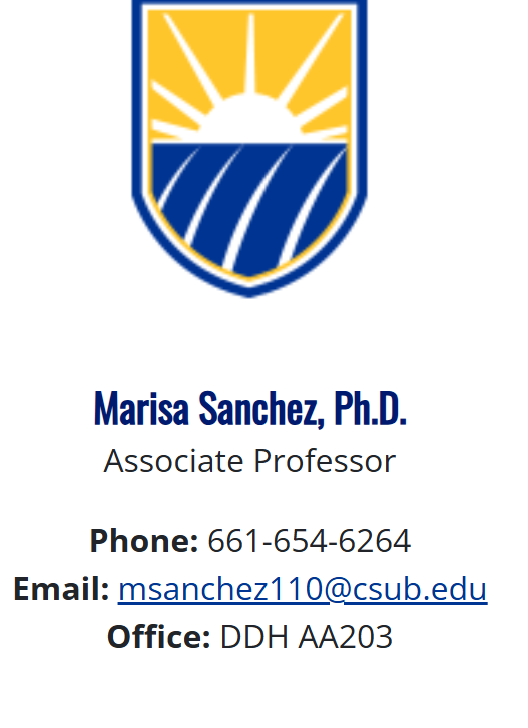
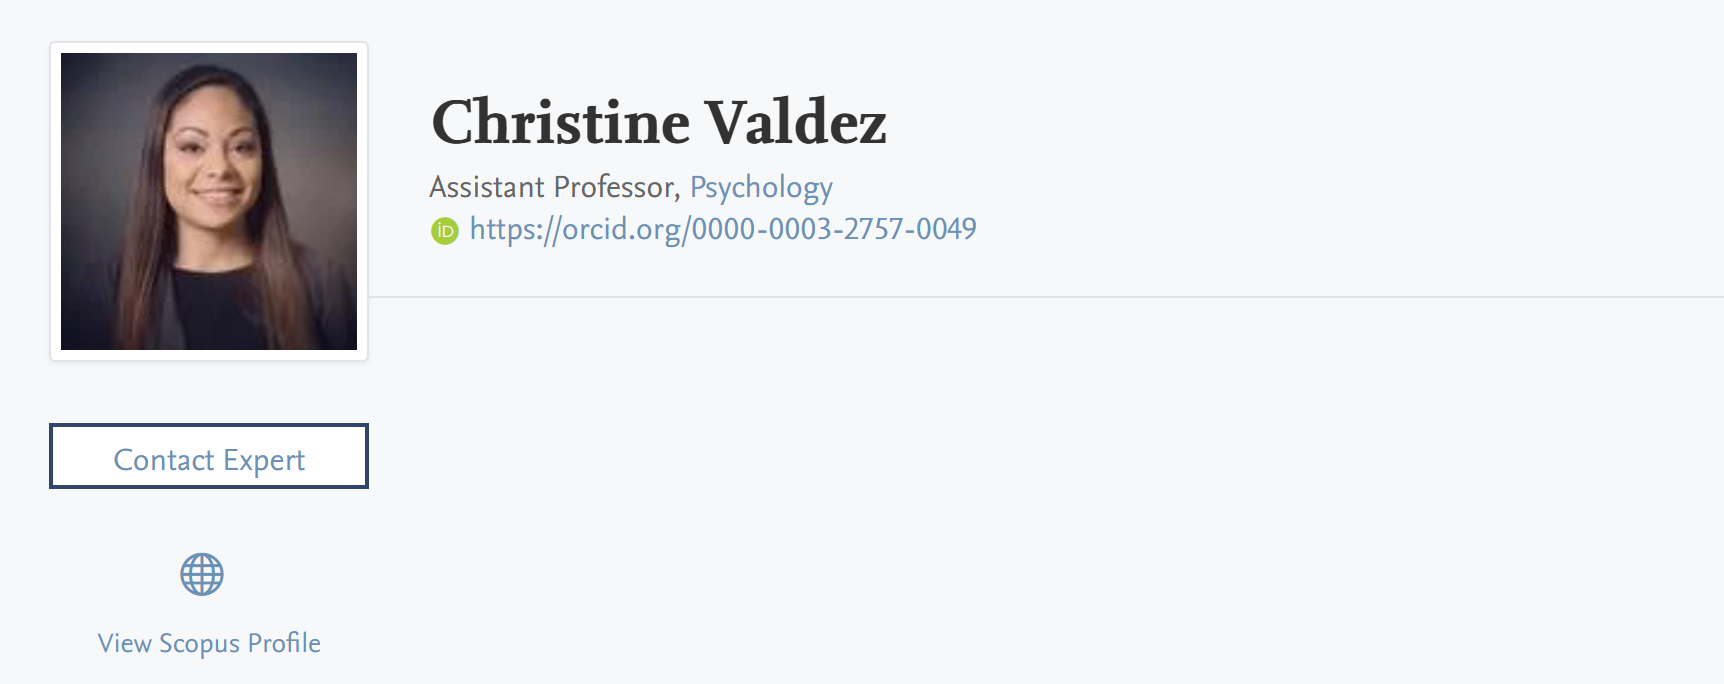
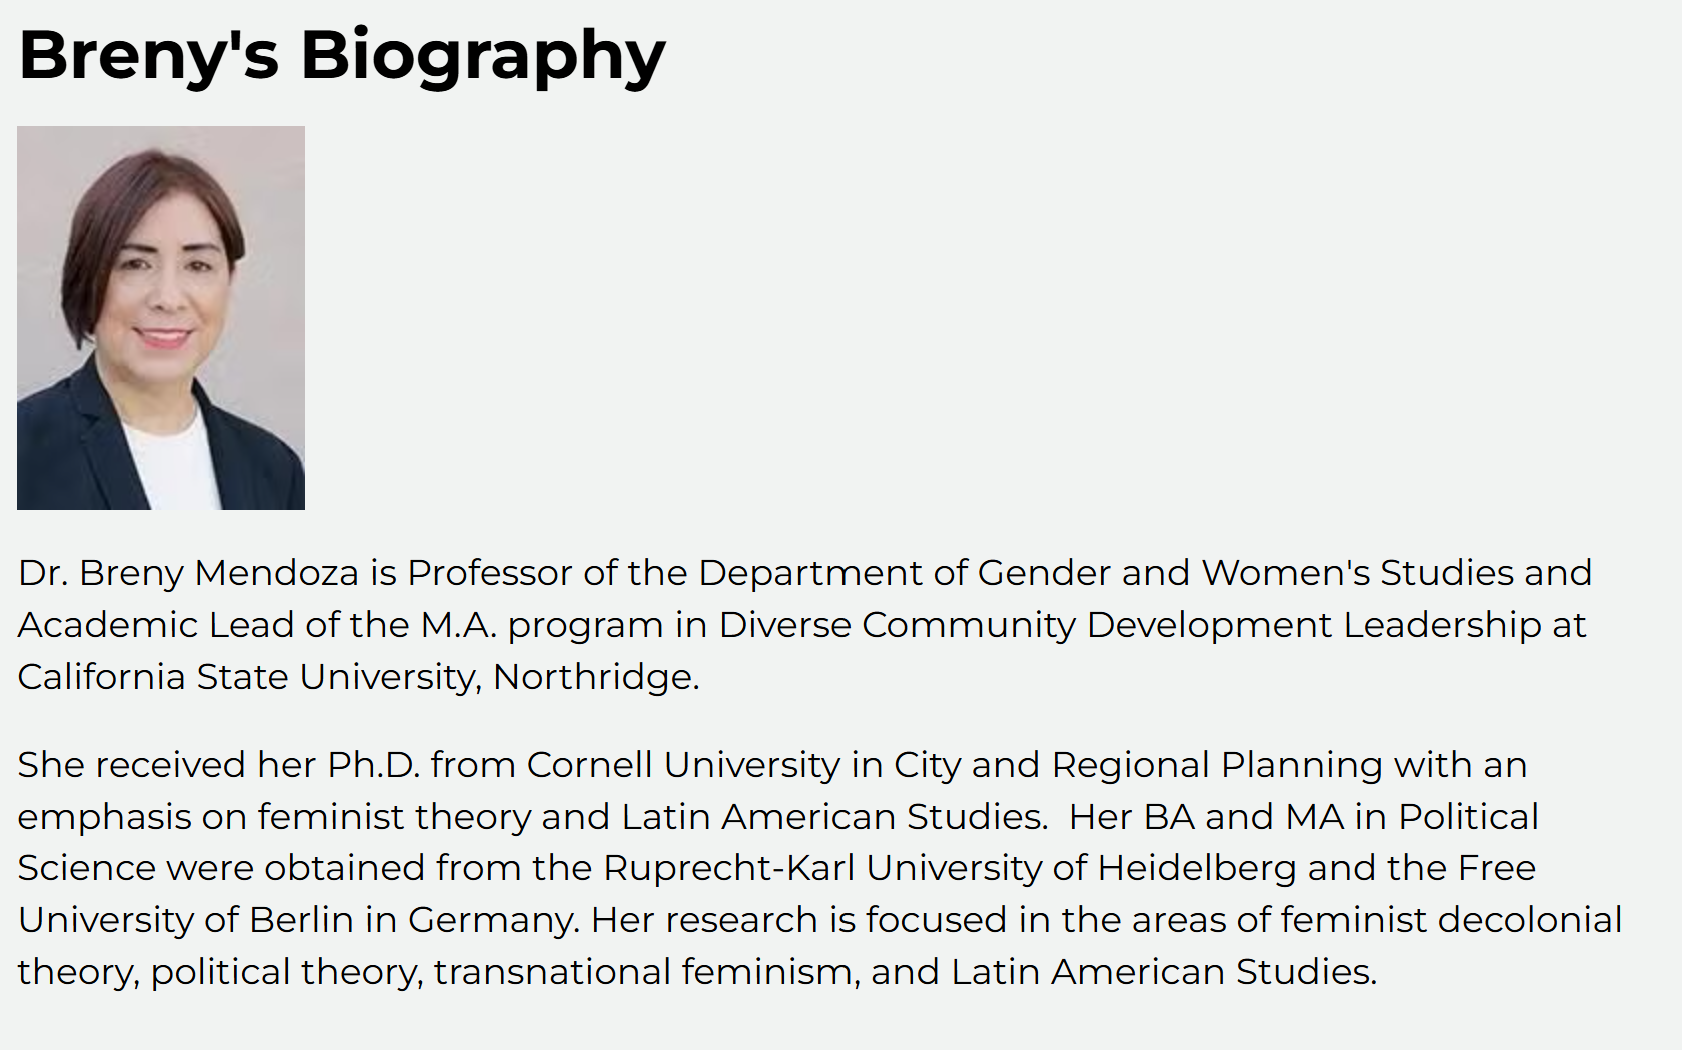
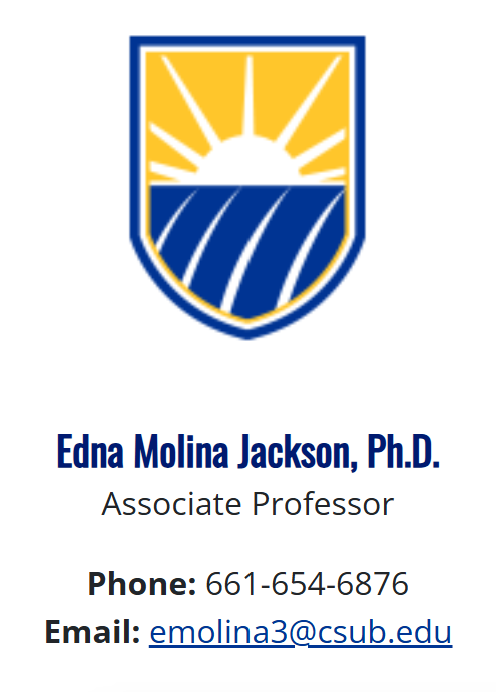

In [44]:
canon_joined = pd.read_parquet('../Data/csu_depbucket_cleaned_joined_pay_2013-2024.parquet')

In [45]:
len(canon_joined[canon_joined['year_transparentCA']==2024])

8242

In [46]:
canon_joined.columns

Index(['year_transparentCA', 'school', 'name', 'title', 'original_department',
       'department', 'total_pay', 'base_pay', 'overtime_pay', 'other_pay'],
      dtype='object')

In [47]:
csu_campus_camps = pd.read_csv('../Data/csu_faculty_count_by_campus.csv')

In [48]:
csu_campus_camps['campus'].unique()

array(['Bakersfield', 'Channel Islands', 'Chico', 'Dominguez Hills',
       'East Bay', 'Fresno', 'Fullerton', 'Humboldt', 'Long Beach',
       'Los Angeles', 'Monterey Bay', 'Northridge', 'Pomona',
       'Sacramento', 'San Bernardino', 'San Diego', 'San Francisco',
       'San Jose', 'San Luis Obispo', 'San Marcos', 'Sonoma',
       'Stanislaus'], dtype=object)

In [49]:
canon_joined['school'].unique()

array(['CSU Bakersfield', 'CSU Channel Islands', 'CSU Long Beach',
       'CSU Northridge', 'CSU San Bernardino', 'Cal Poly Humboldt',
       'Cal Poly Pomona', 'Cal Poly San Luis Obispo',
       'California State University San Marcos',
       'California State University, Chico',
       'California State University, Dominguez Hills',
       'California State University, East Bay',
       'California State University, Fresno',
       'California State University, Fullerton',
       'California State University, Monterey Bay',
       'California State University, Sacramento',
       'California State University, Stanislaus',
       'San Diego State University', 'San Francisco State University',
       'San Jose State University', 'Sonoma State University'],
      dtype=object)

In [50]:
campus_mapping = {
    'Bakersfield': 'CSU Bakersfield',
    'Channel Islands': 'CSU Channel Islands',
    'Chico': 'California State University, Chico',
    'Dominguez Hills': 'California State University, Dominguez Hills',
    'East Bay': 'California State University, East Bay',
    'Fresno': 'California State University, Fresno',
    'Fullerton': 'California State University, Fullerton',
    'Humboldt': 'Cal Poly Humboldt',
    'Long Beach': 'CSU Long Beach',
    'Los Angeles': None,  # No match in the second array
    'Monterey Bay': 'California State University, Monterey Bay',
    'Northridge': 'CSU Northridge',
    'Pomona': 'Cal Poly Pomona',
    'Sacramento': 'California State University, Sacramento',
    'San Bernardino': 'CSU San Bernardino',
    'San Diego': 'San Diego State University',
    'San Francisco': 'San Francisco State University',
    'San Jose': 'San Jose State University',
    'San Luis Obispo': 'Cal Poly San Luis Obispo',
    'San Marcos': 'California State University San Marcos',
    'Sonoma': 'Sonoma State University',
    'Stanislaus': 'California State University, Stanislaus',
}

reverse_campus_mapping = {
    full_name: short_name
    for short_name, full_name in campus_mapping.items()
    if full_name is not None
}

canon_joined['count_campus_name'] = canon_joined['school'].map(reverse_campus_mapping)

In [51]:
canon_joined['count_campus_name'].unique()

array(['Bakersfield', 'Channel Islands', 'Long Beach', 'Northridge',
       'San Bernardino', 'Humboldt', 'Pomona', 'San Luis Obispo',
       'San Marcos', 'Chico', 'Dominguez Hills', 'East Bay', 'Fresno',
       'Fullerton', 'Monterey Bay', 'Sacramento', 'Stanislaus',
       'San Diego', 'San Francisco', 'San Jose', 'Sonoma'], dtype=object)

In [52]:
canon_campus_counts = canon_joined[canon_joined['year_transparentCA']==2024].groupby('count_campus_name').count()['name'].reset_index().copy()

In [53]:
canon_campus_counts = canon_campus_counts.join(csu_campus_camps[['campus', 'all_faculty']].set_index('campus'), on='count_campus_name')

In [55]:
canon_campus_counts.rename(columns={'name': 'count'}, inplace=True)

In [57]:
canon_campus_counts.rename(columns={'all_faculty': 'expected_count'}, inplace=True)

In [58]:
canon_campus_counts

,count_campus_name,count,expected_count
0,Bakersfield,265,598
1,Channel Islands,178,389
2,Chico,488,831
3,Dominguez Hills,255,837
4,East Bay,145,681
5,Fresno,354,1432
6,Fullerton,748,2233
7,Humboldt,275,510
8,Long Beach,465,2451
9,Monterey Bay,231,465


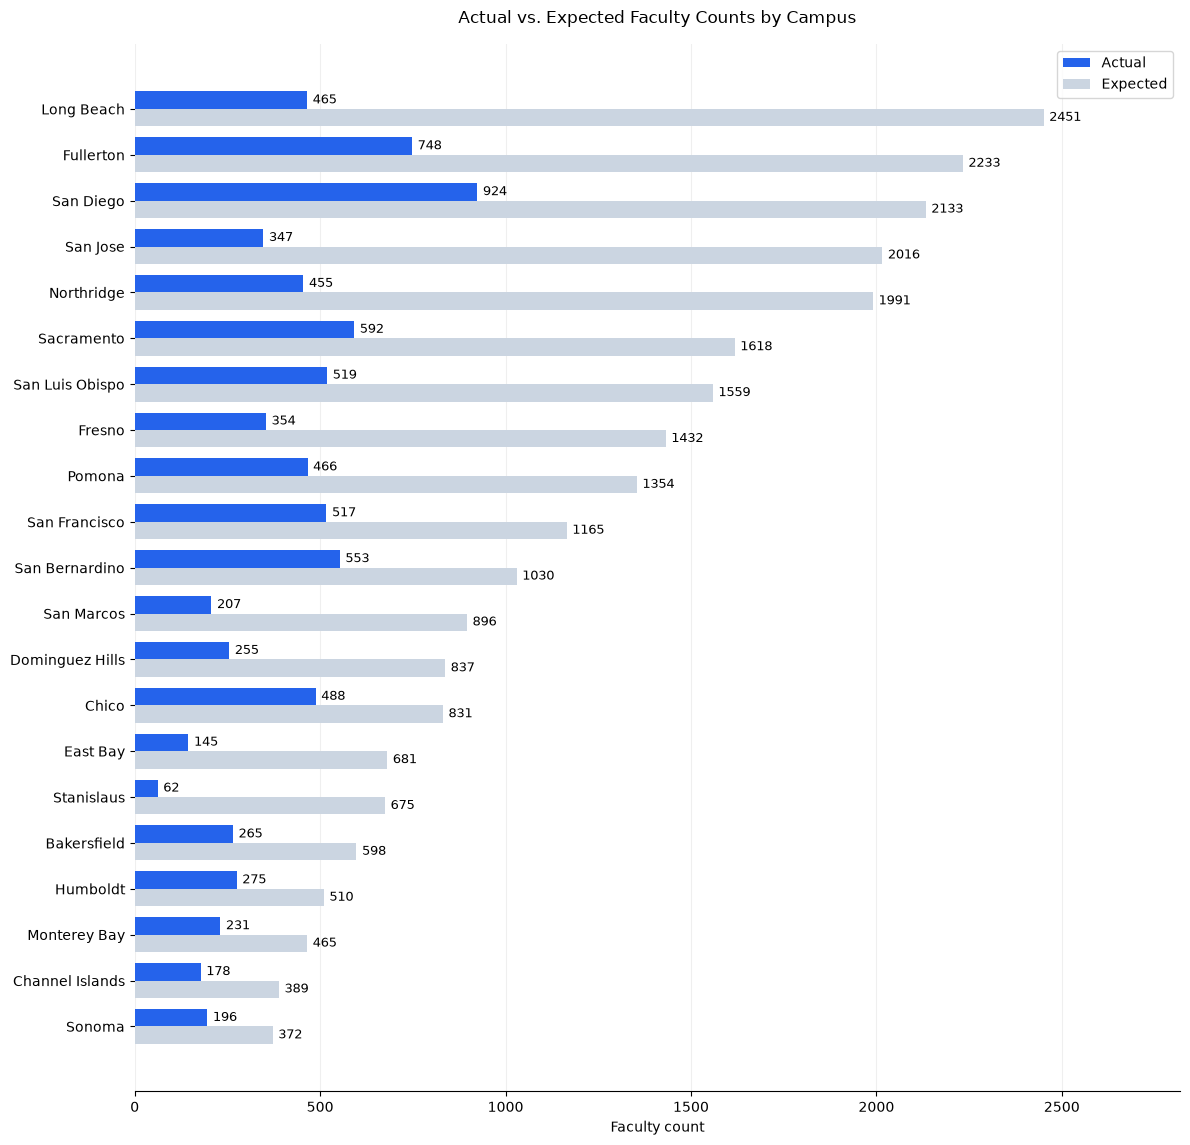

In [59]:
import matplotlib.pyplot as plt
import numpy as np

# Assumes columns: count_campus_name, count, expected_count
df = canon_campus_counts[
    ['count_campus_name', 'count', 'expected_count']
].copy()

df = df.sort_values('expected_count', ascending=False)

y = np.arange(len(df))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(12, max(4, len(df) * 0.55)))

actual = ax.barh(
    y - bar_height / 2,
    df['count'],
    height=bar_height,
    label='Actual',
    color='#2563EB'
)

expected = ax.barh(
    y + bar_height / 2,
    df['expected_count'],
    height=bar_height,
    label='Expected',
    color='#CBD5E1'
)

ax.bar_label(actual, fmt='%.0f', padding=4, fontsize=9)
ax.bar_label(expected, fmt='%.0f', padding=4, fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(df['count_campus_name'])
ax.invert_yaxis()

ax.set_xlabel('Faculty count')
ax.set_title('Actual vs. Expected Faculty Counts by Campus', pad=15)
ax.legend()
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.2)
ax.margins(x=0.15)

for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

In [60]:
csu_campus_camps

,campus,tenure_track_assistant_professor,tenure_track_associate_professor,tenure_track_professor,tenure_track_total,lecturer_total,all_faculty
0,Bakersfield,57,85,89,231,367,598
1,Channel Islands,33,58,76,167,222,389
2,Chico,72,125,202,399,432,831
3,Dominguez Hills,82,96,138,316,521,837
4,East Bay,57,109,154,320,361,681
5,Fresno,124,194,264,582,850,1432
6,Fullerton,150,241,419,810,1423,2233
7,Humboldt,36,79,116,231,279,510
8,Long Beach,194,234,414,842,1609,2451
9,Los Angeles,121,158,260,539,742,1281


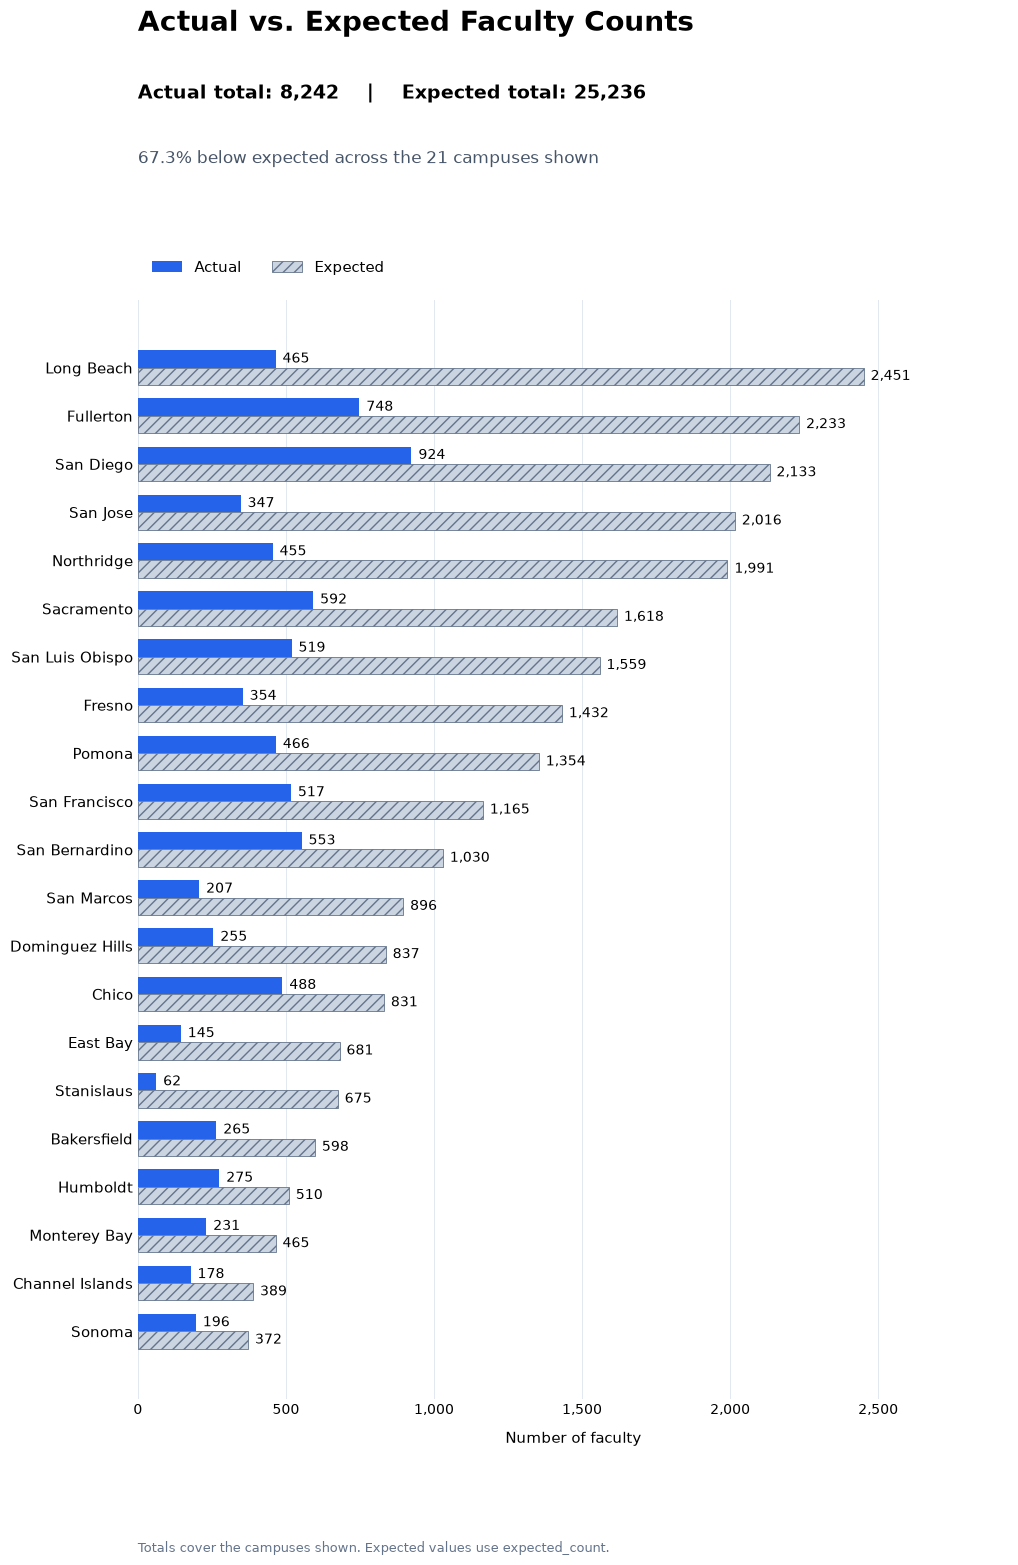

In [62]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import numpy as np
import pandas as pd

df = canon_campus_counts[
    ['count_campus_name', 'count', 'expected_count']
].copy()

# Validate counts so missing values aren't silently counted as zero.
for col in ['count', 'expected_count']:
    df[col] = pd.to_numeric(df[col], errors='raise')

if df.empty or df[['count', 'expected_count']].isna().any().any():
    raise ValueError("Provide non-missing actual and expected counts.")

df = df.sort_values('expected_count', ascending=False)

actual_total = df['count'].sum()
expected_total = df['expected_count'].sum()
difference = actual_total - expected_total

comparison = (
    f"{abs(difference) / expected_total:.1%} "
    f"{'below' if difference < 0 else 'above'} expected"
    if expected_total > 0 and difference != 0
    else "Matches expected total"
    if difference == 0
    else "Expected total is zero"
)

actual_color = '#2563EB'
expected_color = '#CBD5E1'

fig, ax = plt.subplots(
    figsize=(13, max(6, len(df) * 0.65 + 2.5))
)

fig.suptitle(
    'Actual vs. Expected Faculty Counts',
    x=0.30, y=0.98, ha='left',
    fontsize=20, fontweight='bold'
)

fig.text(
    0.30, 0.925,
    f"Actual total: {actual_total:,.0f}    |    "
    f"Expected total: {expected_total:,.0f}",
    fontsize=14, fontweight='bold'
)

fig.text(
    0.30, 0.885,
    f"{comparison} across the {len(df)} campuses shown",
    fontsize=12, color='#475569'
)

y = np.arange(len(df))
height = 0.36

actual = ax.barh(
    y - height / 2, df['count'],
    height=height, color=actual_color, label='Actual'
)

expected = ax.barh(
    y + height / 2, df['expected_count'],
    height=height, color=expected_color,
    edgecolor='#64748B', linewidth=0.6,
    hatch='///', label='Expected'
)

# Values and patterns keep the chart readable without relying on color.
for bars in (actual, expected):
    ax.bar_label(
        bars,
        labels=[f'{bar.get_width():,.0f}' for bar in bars],
        padding=5, fontsize=10
    )

ax.set_yticks(y)
ax.set_yticklabels(df['count_campus_name'], fontsize=11)
ax.invert_yaxis()

largest_value = df[['count', 'expected_count']].max().max()
ax.set_xlim(0, max(1, largest_value * 1.20))
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_xlabel('Number of faculty', fontsize=11, labelpad=10)

ax.set_axisbelow(True)
ax.grid(axis='x', color='#E2E8F0', linewidth=0.7)
ax.tick_params(axis='both', length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(
    loc='lower left', bbox_to_anchor=(0, 1.01),
    ncol=2, frameon=False, fontsize=11
)

fig.text(
    0.30, 0.025,
    'Totals cover the campuses shown. Expected values use expected_count.',
    fontsize=9, color='#64748B'
)

fig.subplots_adjust(left=0.30, right=0.97, top=0.80, bottom=0.12)

# Optional export:
# fig.savefig('faculty_counts.png', dpi=300, bbox_inches='tight')

plt.show()

In [66]:
faculty_labels_canon = pd.read_parquet('../Data/csu_salary_schedule_joined.parquet')

In [69]:
faculty_labels_canon.columns.tolist()

['year_transparentCA',
 'school',
 'name',
 'title',
 'job',
 'original_department',
 'department',
 'total_pay',
 'base_pay',
 'overtime_pay',
 'other_pay',
 'extracted_rank',
 'title_rule',
 'matched_rank',
 'match_method',
 'unmatched_reason',
 'available_range_titles',
 'Class',
 'Range',
 'Effective Date',
 'Class Title',
 'Min Salary',
 'Max Salary',
 'CBID',
 'Status',
 'Status Code',
 'Pay Letter',
 'Abbreviated Title',
 'Range Title',
 'FLSA',
 'SISA',
 'Shift Differential',
 'Occupational Index',
 'Affirmative Action',
 'Employee Category',
 'Vacation Rate',
 'Annual Factor',
 'Budget Occupation',
 'Salary Per',
 'Campus Code',
 'License Type',
 'AY Class',
 'MPP AGL',
 'Pay Plan',
 'Establish Date',
 'Footnote',
 'Record Type',
 'Minimum Rate',
 'Maximum Rate',
 'SSI Rate',
 'Annual Rate',
 'Semester Rate A',
 'Quarter Rate A',
 'Semester Rate B',
 'Quarter Rate B',
 'Semester Rate C',
 'Quarter Rate C',
 'Minimum Rate G',
 'Maximum Rate G',
 'Lecture Rate',
 'Lab Rate',
 'S

In [71]:
faculty_labels_canon = faculty_labels_canon[faculty_labels_canon['year_transparentCA']==2024][['school','matched_rank','name']].copy()

In [72]:
faculty_labels_canon['matched_rank'] = faculty_labels_canon['matched_rank'].apply(lambda x: 'lecturer' if x == 'a' else x)

In [73]:
faculty_labels_canon

,school,matched_rank,name
0,CSU Bakersfield,lecturer,Abigael Flachmann
1,CSU Bakersfield,lecturer,Abolfazl Kiani
2,CSU Bakersfield,professor,Adam Sawyer
3,CSU Bakersfield,professor,Adam Schuster
4,CSU Bakersfield,professor,Adelmira Ynostroza Ochoa
...,...,...,...
11055,Sonoma State University,lecturer,Xiaotian Zhang
11056,Sonoma State University,instructor,Yajuan Xiang
11057,Sonoma State University,instructor,Young Min Chun
11058,Sonoma State University,lecturer,Zachary Sharrett


In [74]:
campus_mapping = {
    'Bakersfield': 'CSU Bakersfield',
    'Channel Islands': 'CSU Channel Islands',
    'Chico': 'California State University, Chico',
    'Dominguez Hills': 'California State University, Dominguez Hills',
    'East Bay': 'California State University, East Bay',
    'Fresno': 'California State University, Fresno',
    'Fullerton': 'California State University, Fullerton',
    'Humboldt': 'Cal Poly Humboldt',
    'Long Beach': 'CSU Long Beach',
    'Los Angeles': None,  # No match in the second array
    'Monterey Bay': 'California State University, Monterey Bay',
    'Northridge': 'CSU Northridge',
    'Pomona': 'Cal Poly Pomona',
    'Sacramento': 'California State University, Sacramento',
    'San Bernardino': 'CSU San Bernardino',
    'San Diego': 'San Diego State University',
    'San Francisco': 'San Francisco State University',
    'San Jose': 'San Jose State University',
    'San Luis Obispo': 'Cal Poly San Luis Obispo',
    'San Marcos': 'California State University San Marcos',
    'Sonoma': 'Sonoma State University',
    'Stanislaus': 'California State University, Stanislaus',
}

reverse_campus_mapping = {
    full_name: short_name
    for short_name, full_name in campus_mapping.items()
    if full_name is not None
}

faculty_labels_canon['count_campus_name'] = faculty_labels_canon['school'].map(reverse_campus_mapping)

In [75]:
faculty_labels_canon

,school,matched_rank,name,count_campus_name
0,CSU Bakersfield,lecturer,Abigael Flachmann,Bakersfield
1,CSU Bakersfield,lecturer,Abolfazl Kiani,Bakersfield
2,CSU Bakersfield,professor,Adam Sawyer,Bakersfield
3,CSU Bakersfield,professor,Adam Schuster,Bakersfield
4,CSU Bakersfield,professor,Adelmira Ynostroza Ochoa,Bakersfield
...,...,...,...,...
11055,Sonoma State University,lecturer,Xiaotian Zhang,Sonoma
11056,Sonoma State University,instructor,Yajuan Xiang,Sonoma
11057,Sonoma State University,instructor,Young Min Chun,Sonoma
11058,Sonoma State University,lecturer,Zachary Sharrett,Sonoma


In [ ]:
# Faculty counts by campus and rank: same count -> join -> rename structure.
import pandas as pd

faculty_labels_canon = pd.read_parquet('../Data/csu_salary_schedule_joined.parquet')
faculty_labels_canon = faculty_labels_canon[
    faculty_labels_canon['year_transparentCA'] == 2024
].copy()

# Original canon filters disabled: use the full 2024 labeled population.
# # ORIGINAL CANON FILTERS: match USE_THIS_CSU_Pipeline.ipynb before counting ranks.
# # Require an accepted faculty title and base pay >= $35,152; exclude explicit
# # part-time titles/departments and recall titles. Keep these fields until filtered.
# import duckdb
# faculty_labels_canon = duckdb.sql(r"""
#     SELECT *
#     FROM faculty_labels_canon
#     WHERE regexp_matches(
#         lower(coalesce(title, '')),
#         '\b(professor|prof|lecturer|lect|instructor|instr|adjunct|adj)\b|\binstructional\s+faculty\b'
#     )
#     AND NOT regexp_matches(
#         lower(coalesce(title, '')),
#         '\bpart[\s\p{Pd}_/]*time\b|\bp[ ./-]*t\b'
#     )
#     AND NOT regexp_matches(
#         lower(coalesce(original_department, '')),
#         '\bpart[\s\p{Pd}_/]*time\b|\bp[ ./-]*t\b'
#     )
#     AND title NOT ILIKE '%recall%'
#     AND base_pay >= 35152
# """).df()
faculty_labels_canon = faculty_labels_canon[['school', 'matched_rank', 'name']].copy()
faculty_labels_canon['matched_rank'] = faculty_labels_canon['matched_rank'].replace({'a': 'lecturer'})
faculty_labels_canon['count_campus_name'] = faculty_labels_canon['school'].map(reverse_campus_mapping)
csu_campus_camps = pd.read_csv('../Data/csu_faculty_count_by_campus.csv')

rank_mapping = {
    'assistant professor': 'tenure_track_assistant_professor',
    'associate professor': 'tenure_track_associate_professor',
    'professor': 'tenure_track_professor',
    'lecturer': 'lecturer_total',
}

# Retain unmatched records for inspection; do not assign them an assumed rank.
faculty_rank_unmatched = faculty_labels_canon.loc[
    ~faculty_labels_canon['matched_rank'].isin(rank_mapping)
    | faculty_labels_canon['count_campus_name'].isna()
].copy()
print(f'Records without a comparable campus/rank: {len(faculty_rank_unmatched):,}')
display(faculty_rank_unmatched['matched_rank'].value_counts(dropna=False))

faculty_expected_rank_counts = csu_campus_camps.melt(
    id_vars='campus', value_vars=list(rank_mapping.values()),
    var_name='matched_rank', value_name='expected_count'
)
faculty_expected_rank_counts['matched_rank'] = faculty_expected_rank_counts['matched_rank'].map(
    {column: rank for rank, column in rank_mapping.items()}
)

canon_campus_rank_counts = faculty_labels_canon[
    faculty_labels_canon['matched_rank'].isin(rank_mapping)
].groupby(['count_campus_name', 'matched_rank']).count()['name'].reset_index().copy()

# Include zero observed counts for ranks at campuses present in the input.
campus_rank_index = pd.MultiIndex.from_product(
    [sorted(faculty_labels_canon['count_campus_name'].dropna().unique()), list(rank_mapping)],
    names=['count_campus_name', 'matched_rank']
)
canon_campus_rank_counts = canon_campus_rank_counts.set_index(
    ['count_campus_name', 'matched_rank']
).reindex(campus_rank_index, fill_value=0).reset_index()

canon_campus_rank_counts = canon_campus_rank_counts.join(
    faculty_expected_rank_counts.set_index(['campus', 'matched_rank']),
    on=['count_campus_name', 'matched_rank'], validate='many_to_one'
)
canon_campus_rank_counts.rename(columns={'name': 'count'}, inplace=True)
if canon_campus_rank_counts['expected_count'].isna().any():
    raise ValueError('Some campus/rank combinations have no expected count.')
display(canon_campus_rank_counts)


In [ ]:
# One axis: color identifies title; solid/hatched bars identify actual/expected.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter
import numpy as np

# Total includes every named record, including instructors and missing ranks.
faculty_campus_totals = faculty_labels_canon.groupby('count_campus_name').count()['name'].reset_index().copy()
faculty_campus_totals = faculty_campus_totals.join(
    csu_campus_camps[['campus', 'all_faculty']].set_index('campus'),
    on='count_campus_name', validate='many_to_one'
)
faculty_campus_totals.rename(
    columns={'name': 'count', 'all_faculty': 'expected_count'}, inplace=True
)
if faculty_campus_totals['expected_count'].isna().any():
    raise ValueError('Some campuses have no expected total.')
faculty_campus_totals = faculty_campus_totals.sort_values('expected_count', ascending=False)
campus_order = faculty_campus_totals['count_campus_name'].tolist()

categories = list(rank_mapping) + ['total']
category_labels = ['Assistant professor', 'Associate professor', 'Professor', 'Lecturer', 'Total faculty']
colors = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#555555']
fig, ax = plt.subplots(figsize=(17, max(9, len(campus_order) * 1.2 + 3)))
y = np.arange(len(campus_order))
category_spacing = 0.17
bar_height = 0.072
largest_value = max(
    canon_campus_rank_counts[['count', 'expected_count']].max().max(),
    faculty_campus_totals[['count', 'expected_count']].max().max()
)

for i, (rank, label, color) in enumerate(zip(categories, category_labels, colors)):
    df = (faculty_campus_totals if rank == 'total' else
          canon_campus_rank_counts.loc[canon_campus_rank_counts['matched_rank'].eq(rank)])
    df = df.set_index('count_campus_name').reindex(campus_order)
    positions = y + (i - (len(categories) - 1) / 2) * category_spacing
    actual = ax.barh(positions - bar_height / 2, df['count'],
                     height=bar_height, color=color, edgecolor=color, linewidth=0.5)
    expected = ax.barh(positions + bar_height / 2, df['expected_count'],
                       height=bar_height, facecolor='white', edgecolor=color,
                       linewidth=0.8, hatch='////')
    for bars in (actual, expected):
        ax.bar_label(bars, labels=[f'{bar.get_width():,.0f}' for bar in bars],
                     padding=3, fontsize=7)

for i in range(0, len(campus_order), 2):
    ax.axhspan(i - 0.5, i + 0.5, color='#F1F5F9', zorder=0)
ax.set_yticks(y)
ax.set_yticklabels(campus_order, fontsize=11)
ax.set_ylim(len(campus_order) - 0.5, -0.5)
ax.set_xlim(0, max(1, largest_value * 1.10))
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_xlabel('Faculty count', fontsize=12)
ax.set_axisbelow(True)
ax.grid(axis='x', color='#E2E8F0', linewidth=0.6)
ax.tick_params(axis='both', length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

fig.suptitle('2024 Faculty Counts by University: Titles and Total',
             fontsize=19, fontweight='bold', y=0.995)
fig.text(0.20, 0.973,
         f'Overall actual: {faculty_campus_totals["count"].sum():,.0f}  |  '
         f'Overall expected: {faculty_campus_totals["expected_count"].sum():,.0f}',
         fontsize=13, fontweight='bold')
category_handles = [Patch(facecolor=color, label=label)
                    for color, label in zip(colors, category_labels)]
fig.legend(handles=category_handles, loc='upper center',
           bbox_to_anchor=(0.58, 0.963), ncol=5, frameon=False, fontsize=10)
fig.legend(handles=[Patch(facecolor='#555555', label='Actual (solid)'),
                    Patch(facecolor='white', edgecolor='#555555', hatch='////',
                          label='Expected (hatched)')],
           loc='upper center', bbox_to_anchor=(0.58, 0.946),
           ncol=2, frameon=False, fontsize=10)
fig.text(0.20, 0.012,
         'Within each university, titles follow the legend order, with total last. Total includes instructors and missing ranks.\n'
         'Counts use non-missing name records. Expected professor counts are tenure-track reference counts; totals cover universities shown.',
         fontsize=9, color='#475569')
fig.subplots_adjust(left=0.20, right=0.97, top=0.92, bottom=0.055)
plt.show()


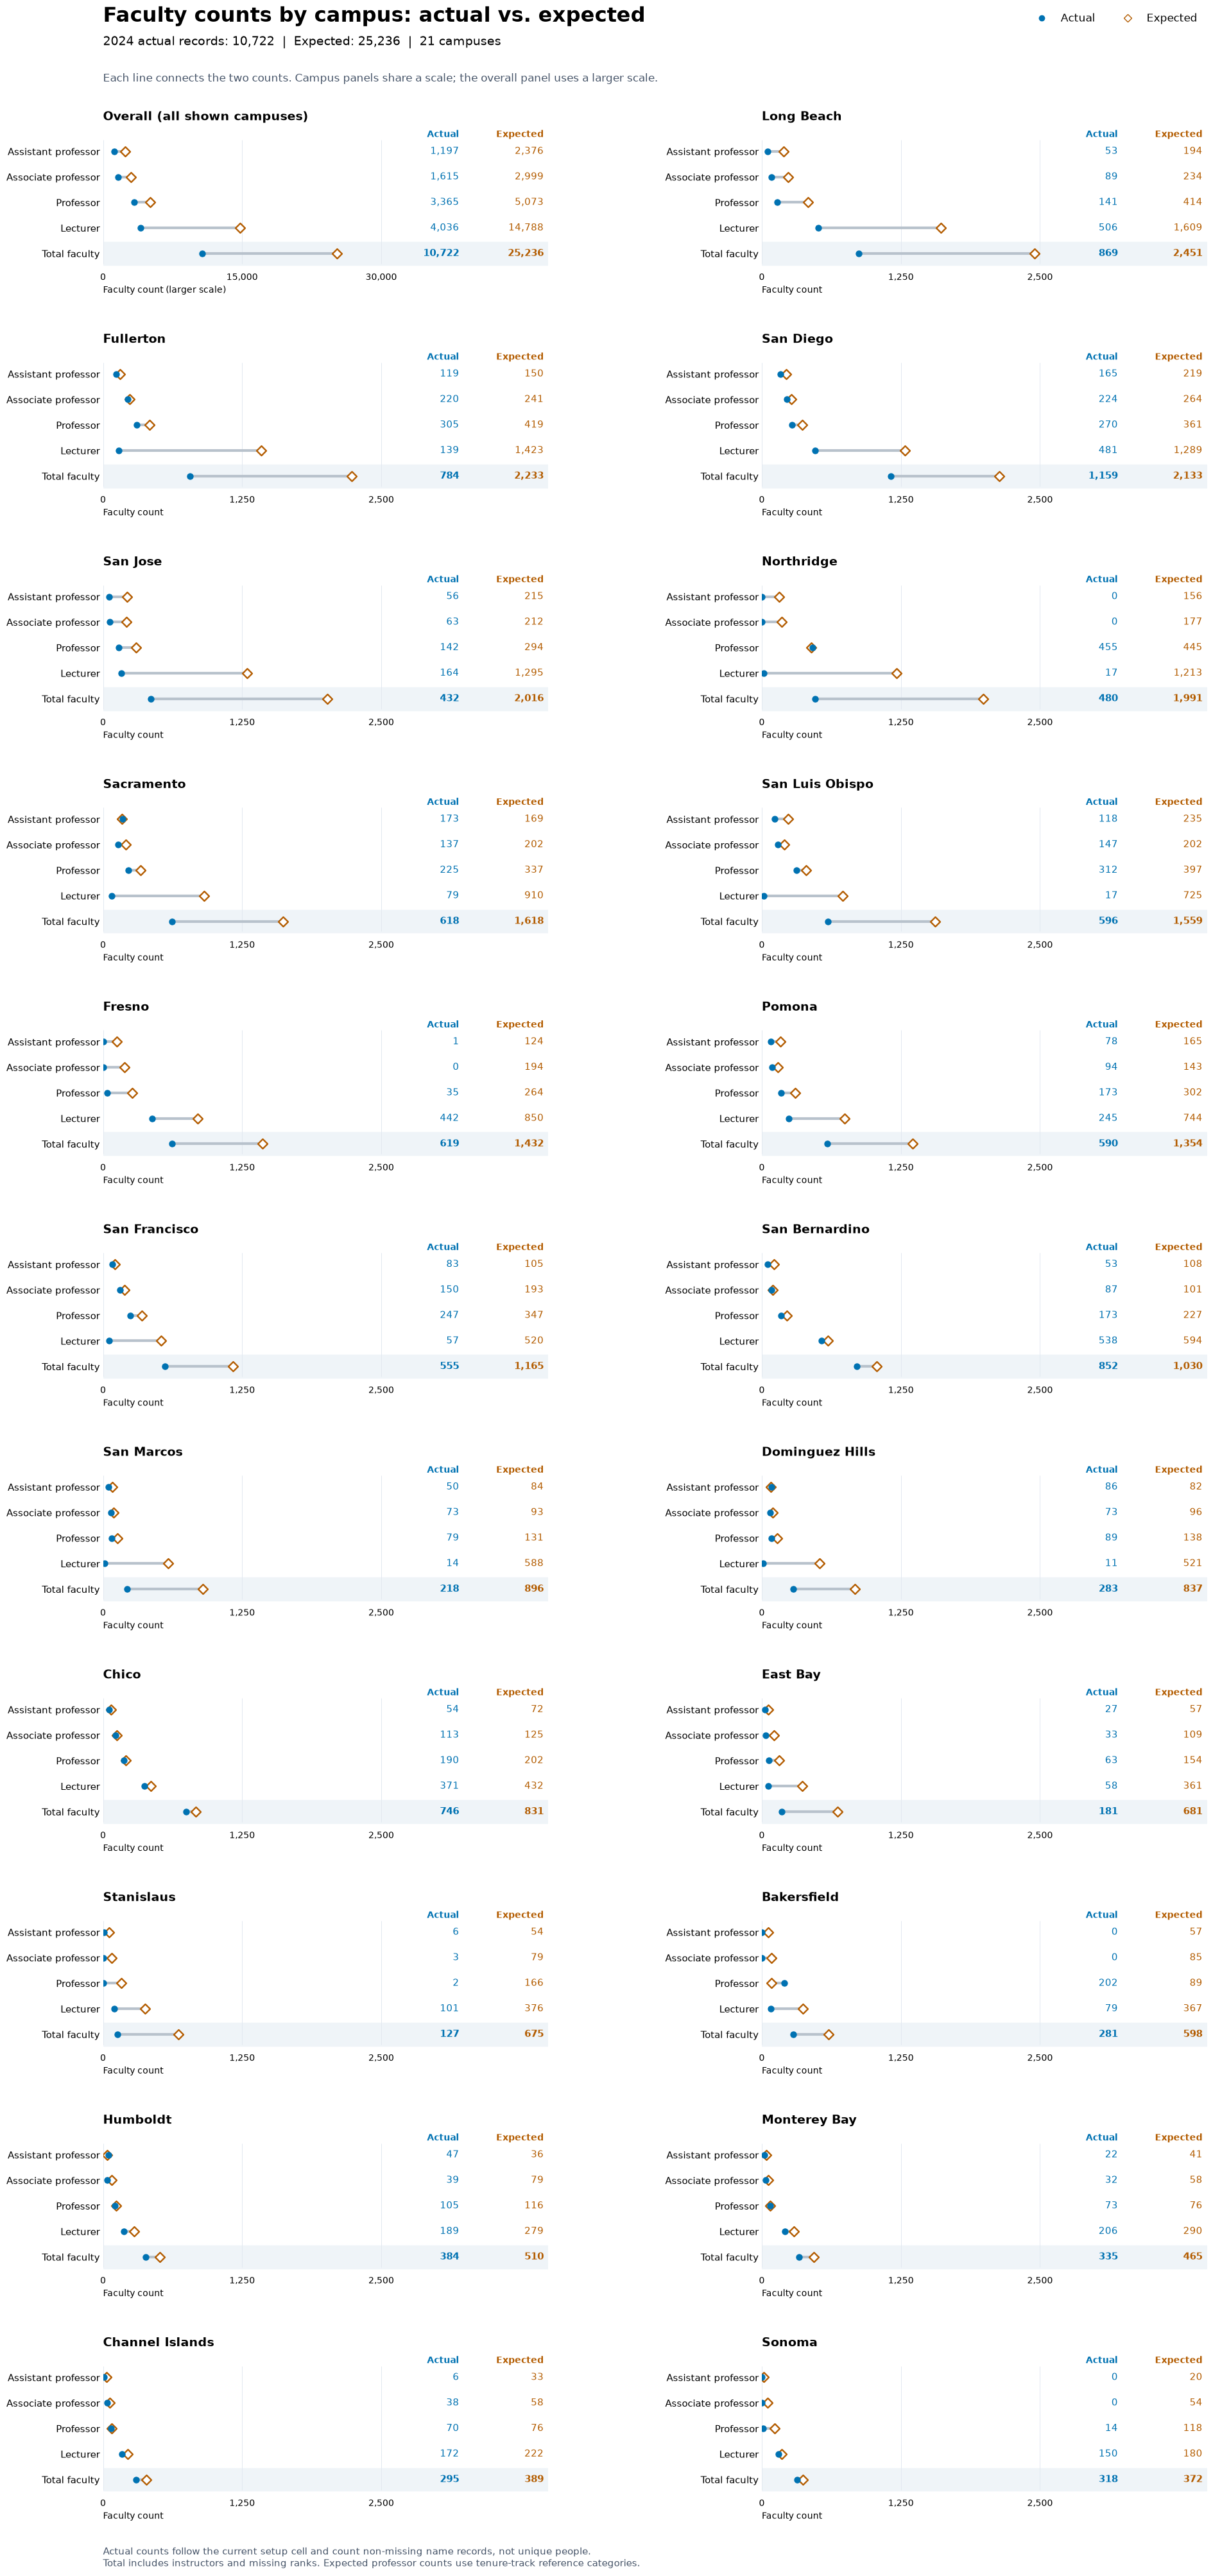

In [84]:
# Alternative: two columns of campus comparison plots (run the rank setup first).
# Connected dots emphasize actual-versus-expected gaps; consistent scales and
# exact-value columns support comparison without overlapping point labels.
# Design reference: https://www.datawrapper.de/academy/how-to-create-a-range-plot
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter
import numpy as np

comparison_totals = faculty_labels_canon.groupby('count_campus_name')['name'].count().rename('count').to_frame()
comparison_totals = comparison_totals.join(
    csu_campus_camps.set_index('campus')['all_faculty'].rename('expected_count'),
    validate='one_to_one'
).sort_values('expected_count', ascending=False)
if comparison_totals.empty or comparison_totals['expected_count'].isna().any():
    raise ValueError('Expected counts are required for every displayed campus.')

rank_order = list(rank_mapping)
row_labels = ['Assistant professor', 'Associate professor', 'Professor', 'Lecturer', 'Total faculty']
campuses = comparison_totals.index.tolist()
# Add an overall summary for exactly the campuses displayed.
panel_names = ['Overall'] + campuses
nrows = (len(panel_names) + 1) // 2
fig, axes = plt.subplots(nrows, 2, figsize=(20, nrows * 3.5 + 2), squeeze=False)
actual_color, expected_color = '#0072B2', '#B35C00'
scale_max = max(comparison_totals.max().max(),
                canon_campus_rank_counts[['count', 'expected_count']].max().max())
scale_max = max(100, np.ceil(scale_max / 500) * 500)
y = np.arange(5)

for ax, campus in zip(axes.flat, panel_names):
    if campus == 'Overall':
        values = canon_campus_rank_counts.loc[
            canon_campus_rank_counts['count_campus_name'].isin(campuses)
        ].groupby('matched_rank')[['count', 'expected_count']].sum().reindex(rank_order)
        totals = comparison_totals[['count', 'expected_count']].sum()
    else:
        values = canon_campus_rank_counts.loc[
            canon_campus_rank_counts['count_campus_name'].eq(campus)
        ].set_index('matched_rank').reindex(rank_order)
        totals = comparison_totals.loc[campus]
    actual = np.append(values['count'].to_numpy(), totals['count'])
    expected = np.append(values['expected_count'].to_numpy(), totals['expected_count'])
    # Overall needs a larger, explicitly labeled scale to preserve campus detail.
    panel_max = (max(1000, np.ceil(max(actual.max(), expected.max()) / 5000) * 5000)
                 if campus == 'Overall' else scale_max)
    ax.axhspan(3.55, 4.45, color='#EFF4F8', zorder=0)
    ax.hlines(y, np.minimum(actual, expected), np.maximum(actual, expected),
              color='#B8C2CC', linewidth=3, zorder=2)
    ax.scatter(expected, y, s=58, marker='D', facecolors='white',
               edgecolors=expected_color, linewidths=1.7, zorder=3)
    ax.scatter(actual, y, s=42, color=actual_color, zorder=4)
    ax.set_yticks(y, row_labels, fontsize=11)
    ax.set_ylim(4.65, -0.8)
    # Reserve a separate area for exact counts; labels never compete with dots.
    ax.set_xlim(0, panel_max * 1.60)
    ax.set_xticks([0, panel_max / 2, panel_max])
    ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.vlines([0, panel_max / 2, panel_max], -0.45, 4.4,
              colors='#E2E8F0', linewidth=0.7, zorder=1)
    for xpos, label, color in [(0.80, 'Actual', actual_color), (0.99, 'Expected', expected_color)]:
        ax.text(xpos, -0.56, label, transform=ax.get_yaxis_transform(),
                ha='right', fontsize=10, fontweight='bold', color=color)
    for row, (observed, reference) in enumerate(zip(actual, expected)):
        weight = 'bold' if row == 4 else 'normal'
        ax.text(0.80, row, f'{observed:,.0f}', transform=ax.get_yaxis_transform(),
                ha='right', va='center', fontsize=11, color=actual_color, fontweight=weight)
        ax.text(0.99, row, f'{reference:,.0f}', transform=ax.get_yaxis_transform(),
                ha='right', va='center', fontsize=11, color=expected_color, fontweight=weight)
    ax.set_title('Overall (all shown campuses)' if campus == 'Overall' else campus,
                 loc='left', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Faculty count (larger scale)' if campus == 'Overall' else 'Faculty count',
                  fontsize=10, loc='left')
    ax.tick_params(axis='both', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

for ax in list(axes.flat)[len(panel_names):]:
    ax.set_visible(False)

fig.suptitle('Faculty counts by campus: actual vs. expected',
             x=0.12, y=0.993, ha='left', fontsize=23, fontweight='bold')
fig.text(0.12, 0.978,
         f'2024 actual records: {comparison_totals["count"].sum():,.0f}  |  '
         f'Expected: {comparison_totals["expected_count"].sum():,.0f}  |  {len(campuses)} campuses',
         fontsize=14)
fig.text(0.12, 0.964,
         'Each line connects the two counts. Campus panels share a scale; the overall panel uses a larger scale.',
         fontsize=12, color='#475569')
fig.legend(handles=[
    Line2D([], [], marker='o', linestyle='none', color=actual_color, label='Actual'),
    Line2D([], [], marker='D', linestyle='none', markerfacecolor='white',
           markeredgecolor=expected_color, label='Expected')
], loc='upper right', bbox_to_anchor=(0.98, 0.994), ncol=2, frameon=False, fontsize=12)
fig.text(0.12, 0.008,
         'Actual counts follow the current setup cell and count non-missing name records, not unique people.\n'
         'Total includes instructors and missing ranks. Expected professor counts use tenure-track reference categories.',
         fontsize=11, color='#475569')
fig.subplots_adjust(left=0.12, right=0.98, top=0.945, bottom=0.035,
                    hspace=0.60, wspace=0.48)
# Optional export for reading at full size:
# fig.savefig('faculty_counts_two_columns.pdf', bbox_inches='tight')
plt.show()
